# Stage 6 (part 2a) — Part-1 follow-ups and deep-model tuning (Prompt 6.3)

| Part | What | Code |
|---|---|---|
| A | Researcher's decisions on Part 1: re-tune Ridge with α up to 1e5; tune the hurdle amount model for **MSESS** | `src/tuning.py` |
| B | 6.3 Tune TSMixer, TiDE and TFT on the DL split (L = 14), 5-seed re-runs, cost vs gain | `src/deep_tuning.py`, `src/deep_ts.py` |

Ablations (Prompt 6.4) are in `06_ablations.ipynb`. The test years (targets 2020–2025) are not touched.

### Step 1 — Setup

**WHAT:** imports, paths, seeds, versions. **WHY:** reproducibility. **Look for:** Optuna 5.0.0, darts 0.48.0, 4 CPUs.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, optuna, torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, splits as S, metrics as M, tuning as T, deep_ts as D, deep_tuning as DT, deep_cls as DC

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0); torch.manual_seed(0); torch.set_num_threads(1)
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 60, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
import darts
print("optuna", optuna.__version__, "| darts", darts.__version__, "| torch", torch.__version__, "| torch threads", torch.get_num_threads())

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


optuna 5.0.0 | darts 0.48.0 | torch 2.14.1+cu130 | torch threads 1


**Interpretation:** same library versions as Part 1. Torch is limited to **one thread** per process: on this 4-core container,
4 torch threads competing with other single-thread jobs made a 50-s TSMixer run take 724 s (OpenMP threads spin-waiting for
cores). With one thread the inner fit takes 14 s.

**Decision:** all Stage-6 deep runs use one torch thread, with parallelism across processes (DECISIONS 6.9).

**Paper note:** *All deep models were trained on CPU with one thread per run; fit times are reported on that basis.*

# Part A — Follow-ups decided after Part 1

### Step 2 — Ridge with α up to 1e5

**WHAT:** the Part-1 Ridge study found its best α (≈ 99) at the upper edge of 1e-4–1e2. As decided, a new 50-trial study searches
1e-4–1e5 (the old study is kept as `models/optuna/ridge__reg__B__range1e-4_1e2.db`). Plot MAE against α for both studies.

**WHY:** a best value at the edge means the range, not the data, chose it. Ridge costs seconds, so widening is cheap. (The boosters'
edge hits were deliberately *not* re-tuned — researcher's decision, DECISIONS 6.7.)

**Why so large an α?** scikit-learn's Ridge penalises α‖w‖² against the *sum* (not mean) of squared errors over ≈ 13,000 rows, so
α = 100 is only ≈ 0.008 per row — still weak shrinkage on standardised features.

**Look for:** whether the new optimum is interior, and whether MAE keeps improving with α (towards a "predict the seasonal mean"
model) at the cost of MSESS.

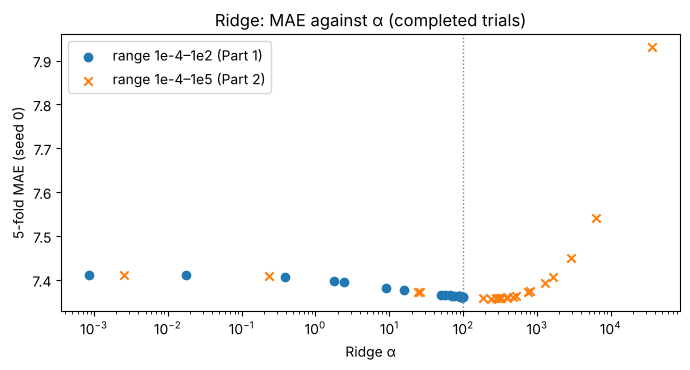

old best α = 99.4, MAE 7.3613 | new best α = 236, MAE 7.3573


In [2]:
T.tune("ridge", "reg", T.BUDGET["reg", "ridge"]); T.rerun_best("ridge", "reg")
old = optuna.load_study(study_name="ridge__reg__B", storage=f"sqlite:///{T.OPTUNA_DIR / 'ridge__reg__B__range1e-4_1e2.db'}")
new = T.load_study("ridge", "reg")
fig, ax = plt.subplots(figsize=(7, 3.8))
for st, lab, mk in ((old, "range 1e-4–1e2 (Part 1)", "o"), (new, "range 1e-4–1e5 (Part 2)", "x")):
    done = [t for t in st.trials if t.state.name == "COMPLETE"]
    ax.scatter([t.params["alpha"] for t in done], [t.value for t in done], marker=mk, label=lab)
ax.axvline(100, color="grey", ls=":", lw=1); ax.set(xscale="log", xlabel="Ridge α", ylabel="5-fold MAE (seed 0)",
                                                   title="Ridge: MAE against α (completed trials)")
ax.legend(); fig.tight_layout(); save(fig, "06_ridge_alpha_range.png"); plt.show()
print("old best α = %.3g, MAE %.4f | new best α = %.3g, MAE %.4f" % (old.best_params["alpha"], old.best_value,
                                                                     new.best_params["alpha"], new.best_value))

**Interpretation:** with the wider range, the best α is **236** (interior). MAE is 7.357 vs 7.361 at α = 99.4, a gain of 0.004 mm.
The curve shows why: MAE is flat between α ≈ 50 and ≈ 800 and only rises steeply beyond 10³, where shrinkage pulls all
coefficients towards zero and Ridge degenerates to a near-constant forecast. Part 1's boundary hit was therefore real but
practically irrelevant: the optimum sat just outside the range, in a flat basin.

**Decision:** Ridge `best_params` updated (α = 236; `best_params_ridge__reg.json`, 5-fold re-run in `cv_results.csv`). The Part-1 study is
archived. The boosters' boundary hits are not re-tuned (researcher's decision, DECISIONS 6.7).

**Paper note:** *Widening the Ridge search range to 10⁵ moved the optimum to α ≈ 236 within a flat basin and changed the cross-validated
MAE by less than 0.01 mm.*

### Step 3 — Hurdle amount model tuned for MSESS

**WHAT:** a second hurdle study (`hurdle_catboost_log_msess`, 30 trials, same CatBoost space) **maximises MSESS** instead of
minimising MAE; P(wet) inside the trials is the default CatBoost classifier, and the 5-seed re-run uses the tuned classifier (as for
the MAE study). Compare default, MAE-tuned and MSESS-tuned hurdle on Set B (5-fold CV), paired across folds, also on seeds 1–4.

**WHY:** the hurdle's role in the paper is the mean-preserving amount forecast (Decision 4.16), so it should be tuned on the
metric that defines that role. Selecting the best-MSESS trial from the MAE study was the cheaper alternative, but that study pruned
trials on MAE, so its MSESS search was censored.

**Look for:** MSESS up and bias near 0, at what cost in MAE.

In [3]:
T.tune("hurdle_catboost_log_msess", "reg", T.BUDGET["reg", "hurdle_catboost_log_msess"])
T.rerun_best("hurdle_catboost_log_msess", "reg"); print("part files merged:", T.merge_results())
cv = pd.read_csv(E.RESULTS)
mae_study = T.load_study("hurdle_catboost_log", "reg")
done = [t for t in mae_study.trials if t.state.name == "COMPLETE"]
print("MAE study: best-MSESS completed trial = %.4f (of %d completed); MSESS study best = %.4f" % (
    max(t.user_attrs["MSESS"] for t in done), len(done), T.load_best("hurdle_catboost_log_msess", "reg")["best_value"]))
for n in ("hurdle_catboost_log", "hurdle_catboost_log_msess"):
    print(n, "best params:", {k: round(v, 4) for k, v in T.load_best(n, "reg")["best_params"].items()})

def fold_mean(model, metric, seeds=None):
    r = cv[(cv.model == model) & (cv.task == "reg") & (cv.feature_set == "B") & (cv.metric == metric)]
    r = r[r.seed.isin(seeds)] if seeds else r
    return r.groupby("fold")["value"].mean()

hm = ["hurdle_catboost_log", "hurdle_catboost_log_tuned", "hurdle_catboost_log_msess_tuned"]
rows = []
for m in hm:
    row = {"model": m}
    for met in ("MAE", "MSESS", "bias", "MAE_wet", "recall_ge20", "recall_ge50"):
        row[met] = fold_mean(m, met).mean()
    d = fold_mean(m, "MSESS") - fold_mean(hm[0], "MSESS")
    row["ΔMSESS vs default"], row["folds better"] = d.mean(), f"{int((d > 0).sum())}/5"
    row["ΔMSESS seeds 1-4"] = (fold_mean(m, "MSESS", [1, 2, 3, 4]) - fold_mean(hm[0], "MSESS", [1, 2, 3, 4])).mean()
    rows.append(row)
hurdle = pd.DataFrame(rows).set_index("model")
hurdle.to_csv(TAB / "06_hurdle_mae_vs_msess.csv"); hurdle.round(4)

part files merged: 21
MAE study: best-MSESS completed trial = 0.2820 (of 11 completed); MSESS study best = 0.2850
hurdle_catboost_log best params: {'depth': 6, 'learning_rate': 0.0369, 'l2_leaf_reg': 3.8818}
hurdle_catboost_log_msess best params: {'depth': 4, 'learning_rate': 0.0823, 'l2_leaf_reg': 1.5107}


,MAE,MSESS,bias,MAE_wet,recall_ge20,recall_ge50,ΔMSESS vs default,folds better,ΔMSESS seeds 1-4
model,,,,,,,,,
hurdle_catboost_log,7.123,0.276,-0.549,11.882,0.446,0.119,0.000e+00,0/5,0.000
hurdle_catboost_log_tuned,7.118,0.278,-0.499,11.880,0.450,0.118,2.100e-03,3/5,0.002
hurdle_catboost_log_msess_tuned,7.125,0.275,-0.477,11.890,0.449,0.122,-8.000e-04,2/5,-0.003


**Interpretation:**
- The MSESS study's best trial reached 0.285 (seed 0, default classifier) vs 0.282, the best MSESS among completed trials of the MAE
  study. Its best setting is shallower and faster (depth 4, learning rate 0.08, `l2_leaf_reg` 1.5).
- **In the 5-seed re-run, which uses the tuned classifier, that advantage disappears:** MSESS 0.275 (MSESS-tuned) vs 0.278
  (MAE-tuned) vs 0.276 (default), better than the default in only 2/5 folds. On seeds 1–4 it is −0.003. MAE (7.12–7.13), bias
  (−0.48 to −0.55 mm/day) and heavy-rain recall are equal within ±0.005.
- Two reasons stack up. The trial score used the default classifier's P(wet) while the re-run uses the tuned one. And seed-0 selection
  optimism (Part 1) is about 0.003 here, the same size as the whole difference. For this model the amount-model hyper-parameters
  hardly matter. Its skill comes from P(wet) × a smeared log-amount, not from tree settings.

**Decision:** the three hurdle configurations are equivalent within noise. The hurdle remains the mean-type finalist. The
MSESS-tuned amount model is used in the ablations (researcher's decision), and the MAE-tuned version is reported alongside it
because it is numerically best. Table: `06_hurdle_mae_vs_msess.csv`.

**Paper note:** *Tuning the hurdle model's amount component for MSESS rather than MAE did not change its cross-validated skill
(|ΔMSESS| ≤ 0.003, within seed variability).*

# Part B — Prompt 6.3: tuning the deep models

### Step 4 — Design

**What is tuned:** hidden size, number of layers, dropout, learning rate and batch size (the playbook's list for 6.3). The playbook
page with the ranges is not in the repository, so the ranges mirror the Stage-6.2 MLP: hidden size {16, 32, 64, 128} (TFT {8, 16, 32, 64},
the slowest model), layers 1–3 (TSMixer blocks; TiDE encoder = decoder layers; TFT LSTM layers 1–2), dropout 0–0.4, learning rate
1e-4–1e-2 (log), batch size {64, 128, 256, 512}. Fixed: lookback L = 14 (Decision 5.8), weight decay 1e-4, ≤ 60 epochs with early
stopping (patience 8), and each model's Stage-5 route — **classification: Bernoulli likelihood** (option 3, raw probability);
**regression: log target + Duan smearing** (TSMixer, TiDE) and **quantile regression with the quantile mean** (TFT).

**Selection on the slice, not on 2015–2019.** A trial fits only the *inner* model (targets ≤ 2011) and is scored on its
out-of-sample forecasts for the 2012–2014 slice (BSS against the inner-years climatology; MAE). The 2015–2019 validation years are
never seen by Optuna. So the validation scores of the re-runs are free of hyper-parameter *selection* optimism; only the slice
score of the best trial is optimistic (it selected the epoch *and* the setting). The price: the slice is shorter (3 years) and
older than the validation period, so the selected setting may not be the best one for 2015–2019.

*Alternative considered:* tuning on 2015–2019 directly (as the classical models were tuned on their validation folds) — rejected,
because with a single split there would be no unbiased validation estimate left before the test set.

**Budget and pruning:** TSMixer and TiDE 20 trials, TFT 12 per task (researcher's decision); seed 0 in every trial;
`TPESampler(seed=42, n_startup_trials=5)` (5 rather than 10 random start-up trials because the budgets are small);
`MedianPruner(n_startup_trials=3, n_warmup_steps=5)` on the slice validation loss after each epoch. **Trial 0 is the Stage-5 default
configuration** (enqueued), so every study shows the default's slice score. One torch thread per process, three studies in parallel.
Re-runs: the best setting with seeds 0–4 through the full protocol (inner fit → best epoch → refit on ≤ 2014 → 2015–2019).

### Step 5 — Run (or load) the six studies

**WHAT:** `DT.tune` (resumes `models/optuna/deep_<model>__<task>.db`), `DT.rerun_best` (5 seeds), `DT.default_scores` (the
stored Stage-5 default runs re-scored with the same code). Budget table: trials, pruned, time, slice score of the default
(trial 0) and of the best trial, parameter count.

**Look for:** how far the best slice score moved from the default, and the cost.

In [4]:
KEYS = [("tsmixer", "cls"), ("tide", "cls"), ("tft", "cls"), ("tsmixer", "reg"), ("tide", "reg"), ("tft", "reg")]
for kind, task in KEYS:
    DT.tune(kind, task); DT.rerun_best(kind, task); DT.default_scores(kind, task)
studies = {k: DT.load_study(*k) for k in KEYS}
rows = []
for (kind, task), st in studies.items():
    b = DT.load_best(kind, task)
    states = pd.Series([t.state.name for t in st.trials]).value_counts()
    rows.append({"model": kind, "task": task, "route": DT.ROUTE[task][kind], "objective (slice)": DT.OBJECTIVE[task][0],
                 "trials": len(st.trials), "pruned": states.get("PRUNED", 0), "failed": states.get("FAIL", 0),
                 "trial_minutes": round(b["trial_minutes"], 1), "default (trial 0)": b["default_value_slice"],
                 "best": b["best_value_slice"], "best_trial": b["best_trial"],
                 "n_params best": int(b["best_user_attrs"]["n_params"]),
                 "n_params default": int(st.trials[0].user_attrs.get("n_params", np.nan))})
budget = pd.DataFrame(rows)
budget.to_csv(TAB / "06_deep_tuning_budget.csv", index=False)
print("total trial time: %.0f min (one thread each)" % budget.trial_minutes.sum())
budget.round(4)

total trial time: 155 min (one thread each)


,model,task,route,objective (slice),trials,pruned,failed,trial_minutes,default (trial 0),best,best_trial,n_params best,n_params default
0,tsmixer,cls,bin,BSS,20,5,0,7.8,0.238,0.262,12,3958,11284
1,tide,cls,bin,BSS,20,8,0,39.5,0.092,0.112,6,270519,27767
2,tft,cls,bin,BSS,12,3,0,45.3,0.231,0.266,9,412927,26975
3,tsmixer,reg,log,MAE,20,7,0,5.6,6.018,5.870,19,2706,11220
4,tide,reg,log,MAE,20,8,0,9.6,6.455,6.358,1,12083,27699
5,tft,reg,mm,MAE,12,5,0,46.8,5.801,5.758,6,30557,26205


**Interpretation:**
- **Compute:** 155 trial-minutes in total (one thread each); wall-clock ≈ 1.7 h with 3 parallel workers, including the 5-seed re-runs.
  TFT dominates (≈ 46 min per task for 12 trials) and the TiDE classifier is next (40 min; its best setting has 270 k parameters).
- **Slice gains are modest except where the default was broken.** BSS: TSMixer 0.238 → 0.262, TFT 0.231 → 0.266, TiDE 0.092 → 0.112.
  TiDE-Bernoulli remains weak on the slice. MAE: TSMixer 6.02 → 5.87, TiDE 6.46 → 6.36, TFT 5.80 → 5.76.
- **Pruning** stopped 3–8 trials per study.
- **Model size moves in both directions:** the tuned TFT classifier has 15× more parameters than the default (413 k vs 27 k), while
  the tuned TSMixers are smaller (2.7–4 k vs 11 k).

**Decision:** budgets as decided (TSMixer/TiDE 20, TFT 12). The studies are stored in `models/optuna/deep_*.db`, best settings
in `models/optuna/best_params_deep_*.json`, and the table in `06_deep_tuning_budget.csv`.

**Paper note:** *The deep models were tuned with 12–20 TPE trials each (about 2.6 CPU-hours in total), selecting on out-of-sample
forecasts for 2012–2014 so that the 2015–2019 validation period remained untouched by the search.*

### Step 6 — Selected settings

**WHAT:** the best parameters per model and task next to the Stage-5 defaults. **WHY:** to see *what* changed — and whether the
networks prefer to be larger or smaller, faster or slower. **Look for:** values at the edge of a range.

In [5]:
rows = []
for (kind, task) in KEYS:
    best, dflt = DT.load_best(kind, task)["best_params"], DT.default_params(kind)
    rows.append({"model": kind, "task": task, **{f"{k}": f"{dflt[k]:g} → {best[k]:.3g}" if isinstance(best[k], float)
                                                 else f"{dflt[k]} → {best[k]}" for k in best}})
best_tab = pd.DataFrame(rows)
best_tab.to_csv(TAB / "06_deep_best_params.csv", index=False); best_tab

,model,task,hidden_size,n_layers,dropout,lr,batch_size
0,tsmixer,cls,32 → 16,2 → 3,0.1 → 0.25,0.001 → 0.00893,256 → 64
1,tide,cls,64 → 128,1 → 3,0.1 → 0.308,0.001 → 0.0083,256 → 128
2,tft,cls,16 → 64,1 → 2,0.1 → 0.0987,0.001 → 0.000396,256 → 128
3,tsmixer,reg,32 → 16,2 → 1,0.1 → 0.0374,0.001 → 0.00209,256 → 64
4,tide,reg,64 → 32,1 → 1,0.1 → 0.0624,0.001 → 0.000131,256 → 64
5,tft,reg,16 → 16,1 → 2,0.1 → 0.0959,0.001 → 0.00798,256 → 256


**Interpretation:** the selected settings have no common pattern:
- **Classification** prefers higher learning rates for TSMixer and TiDE (≈ 0.009) and smaller batches (64–128).
- **Regression** prefers *lower* learning rates for TiDE (1.3e-4) but higher ones for TFT (8e-3).
- **Dropout** is low (0.04–0.10) except for TSMixer-cls and TiDE-cls (0.25–0.31).

When different models and tasks pick very different settings, and Step 10 shows the scores of the best few trials lie close together,
the response surface is flat and noisy. The choice then partly reflects seed and slice noise, not a stable optimum.

**Decision:** report the settings, but interpret no individual hyper-parameter physically for the deep models.

**Paper note:** *The selected deep-model hyper-parameters varied widely across architectures and tasks, consistent with a flat,
noisy objective surface.*

### Step 7 — Validation 2015–2019: default vs tuned, 5 seeds

**WHAT:** for each model and task, the default (Stage 5) and tuned configuration on the validation years: mean ± std over 5 seeds,
seed 0 alone and the mean of seeds 1–4, best epoch, fit time (one thread) and parameter count.

**WHY:** seed 0 was the seed used in the trials; seeds 1–4 were not. Because selection was on the slice, *both* are honest
validation estimates here — the seed-0/seeds-1–4 contrast shows only whether the selected setting relied on a lucky seed.

**Look for:** gains larger than the seed std; whether slice gains (Step 5) carried over to 2015–2019.

In [6]:
res = pd.read_csv(DT.RESULTS)
MET = {"cls": ["BSS", "ROC_AUC", "PR_AUC", "ECE", "CSI"], "reg": ["MAE", "MSESS", "bias", "MAE_wet", "recall_ge50"]}
rows = []
for (kind, task) in KEYS:
    for cfg in ("default", "tuned"):
        r = res[(res.model == kind) & (res.task == task) & (res.config == cfg)]
        piv = r.pivot_table(index="seed", columns="metric", values="value")
        head = MET[task][0]
        row = {"model": kind, "task": task, "config": cfg, "n_seeds": len(piv)}
        for m in MET[task]:
            row[m] = f"{piv[m].mean():.3f} ± {piv[m].std():.3f}"
        row |= {f"{head} seed 0": piv.loc[0, head], f"{head} seeds 1-4": piv.loc[[1, 2, 3, 4], head].mean(),
                "best_epoch": piv["best_epoch"].mean(), "fit_s": piv["fit_seconds"].mean(),
                "n_params": piv["n_params"].mean() if "n_params" in piv and piv["n_params"].notna().any() else np.nan}
        rows.append(row)
val = pd.DataFrame(rows)
val.to_csv(TAB / "06_deep_default_vs_tuned.csv", index=False)
val

,model,task,config,n_seeds,BSS,ROC_AUC,PR_AUC,ECE,CSI,BSS seed 0,BSS seeds 1-4,best_epoch,fit_s,n_params,MAE,MSESS,bias,MAE_wet,recall_ge50,MAE seed 0,MAE seeds 1-4
0,tsmixer,cls,default,5,0.279 ± 0.018,0.964 ± 0.002,0.971 ± 0.002,0.043 ± 0.007,0.854 ± 0.005,0.281,0.278,28.0,47.064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tsmixer,cls,tuned,5,0.266 ± 0.023,0.963 ± 0.001,0.970 ± 0.001,0.039 ± 0.008,0.847 ± 0.007,0.302,0.257,10.0,42.087,3958.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,tide,cls,default,5,0.186 ± 0.008,0.947 ± 0.000,0.952 ± 0.000,0.045 ± 0.002,0.832 ± 0.002,0.194,0.184,60.0,113.977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,tide,cls,tuned,5,0.214 ± 0.003,0.947 ± 0.000,0.952 ± 0.000,0.032 ± 0.003,0.838 ± 0.000,0.215,0.213,21.4,404.444,270519.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,tft,cls,default,5,0.307 ± 0.018,0.965 ± 0.001,0.972 ± 0.002,0.035 ± 0.007,0.856 ± 0.003,0.320,0.303,20.0,227.591,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,tft,cls,tuned,5,0.305 ± 0.016,0.965 ± 0.001,0.972 ± 0.001,0.030 ± 0.005,0.855 ± 0.003,0.317,0.302,14.8,650.841,412927.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,tsmixer,reg,default,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.2,50.895,NaN,9.195 ± 0.136,0.299 ± 0.025,-5.962 ± 0.615,15.015 ± 0.326,0.068 ± 0.029,9.091,9.221
7,tsmixer,reg,tuned,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.2,40.300,2706.0,9.593 ± 0.263,0.225 ± 0.046,-6.867 ± 0.620,15.753 ± 0.497,0.000 ± 0.000,9.690,9.569
8,tide,reg,default,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.0,80.442,NaN,9.434 ± 0.047,0.398 ± 0.001,-0.738 ± 0.195,14.993 ± 0.081,0.233 ± 0.008,9.483,9.422
9,tide,reg,tuned,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.2,198.295,12083.0,9.468 ± 0.034,0.398 ± 0.001,-0.618 ± 0.138,15.040 ± 0.057,0.239 ± 0.007,9.484,9.464


**Interpretation (2015–2019, 5 seeds):**
- **Classification:** TFT tuned 0.305 ± 0.016 vs default 0.307 ± 0.018, a tie. TiDE tuned 0.214 vs 0.186: a real gain, because the default
  was stuck at the 60-epoch cap (Decision 5.12) and the higher learning rate converges in ≈ 21 epochs. TSMixer tuned 0.266 vs 0.279: worse.
  The TSMixer seed-0 BSS of 0.302 against 0.257 for seeds 1–4 shows a strong seed effect that persists into validation for the same
  initialisation.
- **Regression:** no tuned model beats its default on MAE. TSMixer 9.59 vs 9.19, TFT 9.26 vs 9.18, TiDE 9.47 vs 9.43. MSESS is unchanged
  for TiDE (0.398) and TFT (0.280) and drops for TSMixer (0.225 vs 0.299).
- **Cost:** the tuned TFT classifier takes 651 s per fit vs 228 s, and the tuned TiDE classifier 404 s vs 114 s, for no gain or a small one.

**Why slice gains did not transfer:** the slice (2012–2014) is a different regime from the validation period (2015–2019, wetter after
the 2016 step; Decision 1.9). A setting that fits the slice better is not the one that extrapolates best across the break. Seed noise
(std 0.02 BSS, 0.1–0.3 mm MAE) is also as large as the differences between good settings.

**Decision:** for the deep models, the Stage-5 defaults are kept as headline configurations except TiDE-classification (tuned). The
tuned versions are reported as a sensitivity result. Seed 0 vs seeds 1–4 is reported, but here it reflects seed luck carried
forward, not selection optimism, because selection used the slice.

**Paper note:** *Tuning the deep models on a held-out 2012–2014 slice did not improve their 2015–2019 skill (TFT ΔBSS ≈ 0; regression
MAE unchanged or worse), except for TiDE classification, whose default configuration had not converged.*

### Step 8 — Is the tuned − default difference real? (paired monthly block bootstrap)

**WHAT:** seed-mean forecasts of the tuned and the default configuration, same validation days; 1,000 resamples of calendar months
of the target date; ΔBSS (tuned − default, > 0 = better), ΔMAE (< 0 = better), ΔMSESS. The default runs used up to 4 torch threads and
the tuned runs 1 thread (no effect on the comparison; results of one configuration are thread-independent up to rounding).

**WHY:** 5 seeds × one validation period gives no fold structure; the bootstrap over months is our standard uncertainty for the
DL split (Decision 5.10). **Look for:** CIs that exclude 0.

In [7]:
def seed_mean(kind, task, cfg):
    tr = DT.ROUTE[task][kind]
    col = "p" if task == "cls" else DT.POINT[tr]
    folder, stem = (DT.TUNED_DIR, DT.tag(kind, task)) if cfg == "tuned" else (D.DEEP_DIR, f"{kind}_{tr}_L14")
    return np.mean([pd.read_parquet(folder / f"{stem}__seed{s}.parquet")[col].to_numpy() for s in range(5)], axis=0)

rows = []
for (kind, task) in KEYS:
    va, y, refs = DT.references(task)
    y, clim = y.to_numpy(), np.asarray(refs["climatology"])
    a, b = seed_mean(kind, task, "tuned"), seed_mean(kind, task, "default")
    fns = {"dBSS": lambda yy, p, q, c: (np.mean((q - yy) ** 2) - np.mean((p - yy) ** 2)) / np.mean((c - yy) ** 2)} if task == "cls" else \
          {"dMAE": lambda yy, p, q, c: np.mean(np.abs(p - yy)) - np.mean(np.abs(q - yy)),
           "dMSESS": lambda yy, p, q, c: (np.mean((q - yy) ** 2) - np.mean((p - yy) ** 2)) / np.mean((c - yy) ** 2)}
    for met, fn in fns.items():
        est, lo, hi = M.block_bootstrap(fn, S.target_dates(va), y, a, b, clim)
        rows.append({"model": kind, "task": task, "metric": met, "estimate": est, "ci_low": lo, "ci_high": hi,
                     "significant": bool(lo > 0 or hi < 0)})
boot = pd.DataFrame(rows)
boot.to_csv(TAB / "06_deep_tuned_vs_default_bootstrap.csv", index=False); boot.round(4)

,model,task,metric,estimate,ci_low,ci_high,significant
0,tsmixer,cls,dBSS,-1.570e-02,-0.041,4.900e-03,False
1,tide,cls,dBSS,2.730e-02,0.016,4.010e-02,True
2,tft,cls,dBSS,6.100e-03,-0.003,1.610e-02,False
3,tsmixer,reg,dMAE,3.879e-01,0.211,5.713e-01,True
4,tsmixer,reg,dMSESS,-7.150e-02,-0.089,-5.250e-02,True
5,tide,reg,dMAE,3.410e-02,0.023,4.690e-02,True
6,tide,reg,dMSESS,-2.000e-04,-0.002,7.000e-04,False
7,tft,reg,dMAE,7.830e-02,0.031,1.243e-01,True
8,tft,reg,dMSESS,1.100e-03,-0.005,6.400e-03,False


**Interpretation:** the bootstrap confirms Step 7.
- **TiDE classification** is the only significant gain (ΔBSS +0.027, CI 0.016–0.040).
- **Regression gets significantly worse in MAE after tuning:** TSMixer +0.39 mm (CI 0.21–0.57; also ΔMSESS −0.07), TFT +0.08 mm
  (0.03–0.12), TiDE +0.03 mm (0.02–0.05).
- TFT and TSMixer classification differences include 0.

These CIs come from seed-mean forecasts and resample months; they ignore seed-to-seed variance and are not multiplicity-corrected
(9 tests).

**Decision:** as in Step 7. The negative result is reported, not hidden.

**Paper note:** *Paired block-bootstrap tests showed that tuning significantly degraded the deep regressors' validation MAE (by 0.03–0.39
mm) and significantly improved only the non-converged TiDE classifier (ΔBSS +0.027, 95 % CI 0.016–0.040).*

### Step 9 — Cost versus gain, next to the tuned classical models on the same split

**WHAT:** refit the two leading tuned classical models on the DL split (training 1981–2014, validation 2015–2019; 5 seeds, one
thread): **LightGBM** (classification) and **CatBoost Tweedie** (regression). Then plot skill against compute: fit time per run
and the total tuning time, for the deep models (default → tuned) and the classical models.

**WHY:** "does tuning make the deep models competitive, and at what price?" is the question the paper must answer. The comparison
must be on identical validation days (rule 7).

**Look for:** whether any tuned deep model reaches the tuned classical model, and how many CPU-minutes each point costs.

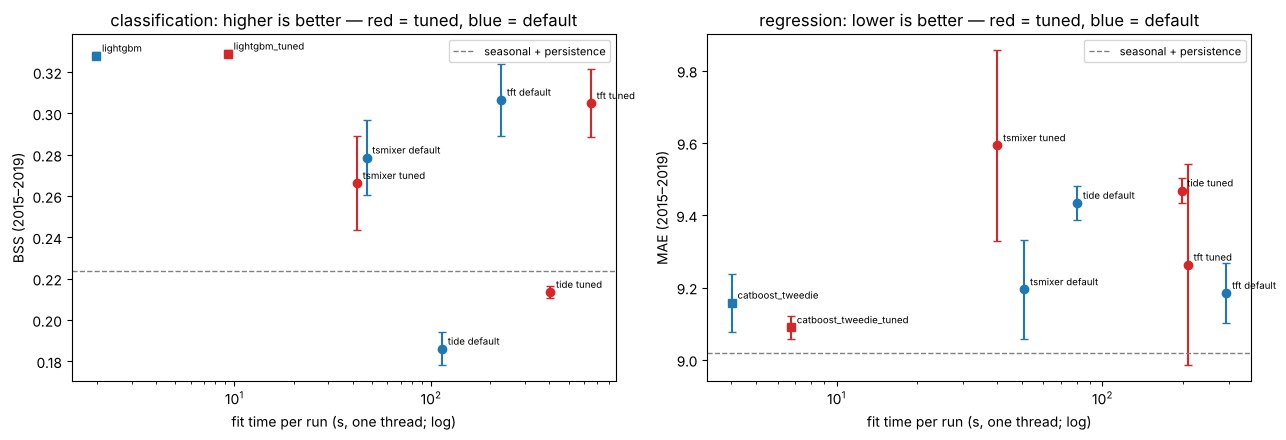

,model,task,family,metric,value,seed_std,fit_s,tuning_min
0,lightgbm_tuned,cls,classical,BSS,0.329,0.002,9.286,53.840
1,catboost_tweedie_tuned,reg,classical,MAE,9.089,0.032,6.756,29.030
2,lightgbm,cls,classical,BSS,0.328,0.002,1.989,0.000
3,catboost_tweedie,reg,classical,MAE,9.158,0.080,4.042,0.000
4,tsmixer default,cls,deep,BSS,0.279,0.018,47.064,0.000
5,tsmixer tuned,cls,deep,BSS,0.266,0.023,42.087,7.840
6,tide default,cls,deep,BSS,0.186,0.008,113.977,0.000
7,tide tuned,cls,deep,BSS,0.213,0.003,404.444,39.514
8,tft default,cls,deep,BSS,0.307,0.018,227.591,0.000
9,tft tuned,cls,deep,BSS,0.305,0.016,650.841,45.308


In [8]:
for name, task, model in (("lightgbm_tuned", "cls", "lightgbm"), ("catboost_tweedie_tuned", "reg", "catboost_tweedie")):
    build = T.MODELS[task][model][1](T.load_best(model, task)["best_params"], task)
    for seed in range(5):
        if not (E.SPLITS["dl"][2] / f"{name}__{task}__B__seed{seed}.parquet").exists():
            E.run_cv(name, build, task, "B", seed, split="dl")
dl = pd.read_csv(E.SPLITS["dl"][1])
pts = []
for name, task, model, tm in (("lightgbm_tuned", "cls", "lightgbm", "BSS"), ("catboost_tweedie_tuned", "reg", "catboost_tweedie", "MAE"),
                              ("lightgbm", "cls", None, "BSS"), ("catboost_tweedie", "reg", None, "MAE")):
    r = dl[(dl.model == name) & (dl.feature_set == "B") & (dl.task == task)]
    pts.append({"model": name, "task": task, "family": "classical", "metric": tm, "value": r[r.metric == tm].value.mean(),
                "seed_std": r[r.metric == tm].groupby("seed").value.mean().std(),
                "fit_s": r[r.metric == "fit_seconds"].value.mean(),
                "tuning_min": sum(t.duration.total_seconds() for t in T.load_study(model, task).trials if t.duration) / 60
                if model else 0.0})
for (kind, task) in KEYS:
    tm = DT.OBJECTIVE[task][0]
    for cfg in ("default", "tuned"):
        r = res[(res.model == kind) & (res.task == task) & (res.config == cfg)]
        pts.append({"model": f"{kind} {cfg}", "task": task, "family": "deep", "metric": tm,
                    "value": r[r.metric == tm].value.mean(), "seed_std": r[r.metric == tm].value.std(),
                    "fit_s": r[r.metric == "fit_seconds"].value.mean(),
                    "tuning_min": DT.load_best(kind, task)["trial_minutes"] if cfg == "tuned" else 0.0})
for task, tm, base in (("cls", "BSS", "baseline:seasonal+persistence"), ("reg", "MAE", "baseline:seasonal+persistence")):
    r = dl[(dl.model == base) & (dl.task == task) & (dl.metric == tm)]
    pts.append({"model": "seasonal+persistence", "task": task, "family": "baseline", "metric": tm, "value": r.value.mean(),
                "seed_std": 0.0, "fit_s": np.nan, "tuning_min": 0.0})
cost = pd.DataFrame(pts)
cost.to_csv(TAB / "06_deep_cost_vs_skill.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, task in zip(axes, ("cls", "reg")):
    c = cost[(cost.task == task) & (cost.family != "baseline")]
    for _, r in c.iterrows():
        ax.errorbar(r.fit_s, r.value, yerr=r.seed_std, fmt="o" if r.family == "deep" else "s",
                    color="tab:red" if "tuned" in r.model else "tab:blue", capsize=3)
        ax.annotate(r.model, (r.fit_s, r.value), fontsize=7, xytext=(4, 3), textcoords="offset points")
    sp = cost[(cost.task == task) & (cost.family == "baseline")].value.iloc[0]
    ax.axhline(sp, color="grey", ls="--", lw=1, label="seasonal + persistence")
    ax.set(xscale="log", xlabel="fit time per run (s, one thread; log)", ylabel=c.metric.iloc[0] + " (2015–2019)",
           title=("classification: higher is better" if task == "cls" else "regression: lower is better")
           + " — red = tuned, blue = default")
    ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "06_deep_cost_vs_skill.png"); plt.show()
cost.round(4)

**Interpretation (identical 2015–2019 validation days):**
- **Classification:** tuned LightGBM reaches BSS **0.329 ± 0.002** (default 0.328) in **9 s** per fit, against **0.305–0.307** for the best deep
  model (TFT) at 230–650 s per fit. That is ≈ 25–70× the time, plus 45 min of tuning, for 0.02 less BSS. All tuned deep classifiers except
  TiDE beat seasonal + persistence (0.224).
- **Regression:** tuned CatBoost Tweedie reaches MAE **9.09 ± 0.03** (default 9.16). **No model, classical or deep, beats seasonal + persistence
  on MAE in 2015–2019 (9.02).** This repeats Stage 5. The post-2016 wet regime defeats MAE-oriented models trained mostly on drier years.
  The deep models are 0.1–0.5 mm worse than Tweedie, at 6–40× the fit time.
- **Cost vs gain:** classical tuning bought +0.001 BSS / −0.07 mm on this split for ≈ 30–55 min of tuning. Deep tuning bought nothing or
  less for ≈ 10–47 min per model.

**Decision:** the deep models do not earn their compute as point forecasters (Decision 5.13 confirmed after tuning). The DL-split
refits of the tuned classical models are stored in `dl_results.csv` / `models/dl/`, and the table in `06_deep_cost_vs_skill.csv`.

**Paper note:** *On the common 2015–2019 validation period, the tuned gradient-boosting classifier outperformed the best tuned deep model
(BSS 0.329 vs 0.305) at roughly 1/70 of the training time, and no model beat seasonal persistence in MAE.*

### Step 10 — Optimisation histories of the six deep studies

**WHAT:** slice objective per trial (trial 0 = default, highlighted), best-so-far line, pruned trials marked at the bottom.
**WHY:** with 12–20 trials we must check whether the search had converged. **Look for:** improvements late in the study (budget
too small) vs a plateau.

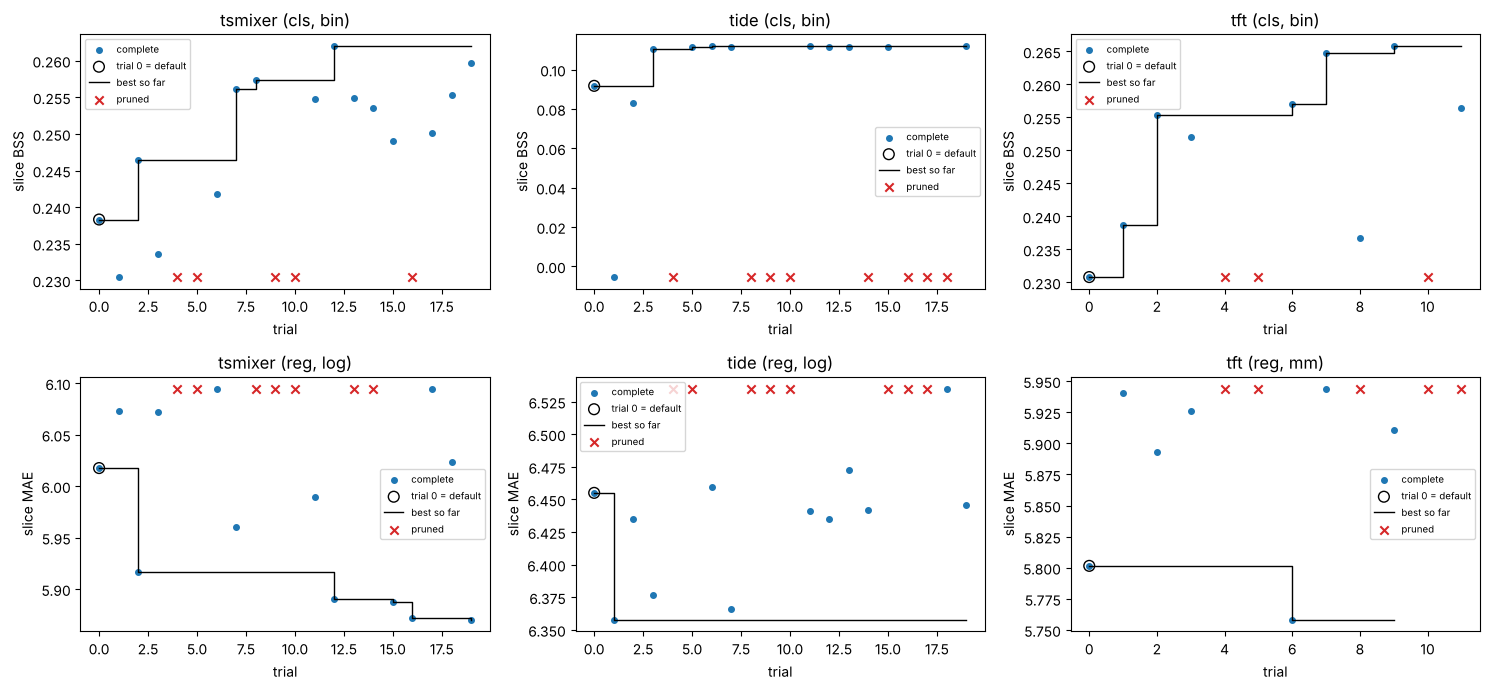

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (kind, task) in zip(axes.ravel(), [k for k in KEYS if k[1] == "cls"] + [k for k in KEYS if k[1] == "reg"]):
    st = studies[kind, task]
    done = [t for t in st.trials if t.state.name == "COMPLETE"]
    vals = pd.Series({t.number: t.value for t in done}).sort_index()
    ax.scatter(vals.index, vals.values, s=16, label="complete")
    ax.scatter([0], [st.trials[0].value], s=60, facecolors="none", edgecolors="k", label="trial 0 = default")
    ax.step(vals.index, vals.cummax() if task == "cls" else vals.cummin(), where="post", color="k", lw=1, label="best so far")
    pr = [t.number for t in st.trials if t.state.name == "PRUNED"]
    if pr:
        ax.scatter(pr, np.full(len(pr), vals.min() if task == "cls" else vals.max()), marker="x", color="tab:red", label="pruned")
    ax.set(title=f"{kind} ({task}, {DT.ROUTE[task][kind]})", xlabel="trial", ylabel=f"slice {DT.OBJECTIVE[task][0]}")
    ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "06_deep_optuna_history.png"); plt.show()

**Interpretation:**
- Classification studies kept improving until trials 9–12 and then plateaued (TiDE-cls after trial 3).
- Regression is noisier: the best TiDE trial is trial 1 and the best TFT trial is trial 6 (of 12). After those, later trials scatter
  above the best. Together with Step 7, this means the slice objective was largely noise-limited.
- A larger budget would have found slightly better *slice* scores. Given that slice gains did not transfer, more trials are not
  the bottleneck.

**Decision:** no extra trials. If the deep models are ever revisited, the most useful change is a selection period closer to the
deployment regime (e.g. a rolling slice), not a larger search.

**Paper note:** *The optimisation histories plateaued within the trial budgets; the limiting factor was the transfer of slice performance to
the later validation regime, not the size of the search.*

### Part 2a — summary

1. **Ridge (α up to 1e5):** optimum α ≈ 236 (interior), MAE −0.004 mm. The Part-1 boundary hit was practically irrelevant.
2. **Hurdle tuned for MSESS:** equivalent to the default and the MAE-tuned hurdle (|ΔMSESS| ≤ 0.003 on 5 seeds). The mean-type
   hurdle's skill does not depend on its amount-model hyper-parameters.
3. **Deep tuning (6.3), selected on the 2012–2014 slice:** better slice scores, but **no transfer to 2015–2019**. TFT-cls tied (0.305 vs 0.307),
   all regressors significantly worse or equal on MAE, TSMixer worse in both tasks. The only gain is TiDE-cls (+0.027 BSS, a convergence fix).
   About 2.6 CPU-hours of trials.
4. **Cost vs skill on identical days:** tuned LightGBM BSS 0.329 in 9 s vs TFT 0.305 in 230–650 s. Tuned Tweedie MAE 9.09 vs deep 9.2–9.6.
   Nothing beats seasonal + persistence on 2015–2019 MAE (9.02).

Outputs: `src/deep_tuning.py`, extended `src/deep_ts.py` (parameters, variants, inner-only mode; Stage-5 defaults reproduced exactly);
`models/optuna/deep_*.db`, `best_params_deep_*.json`, `models/deep/tuned/`; tables `06_hurdle_mae_vs_msess.csv`, `06_deep_tuning_budget.csv`,
`06_deep_best_params.csv`, `06_deep_default_vs_tuned.csv`, `06_deep_tuned_vs_default_bootstrap.csv`, `06_deep_cost_vs_skill.csv`,
`deep_tuned_results.csv`; figures `06_ridge_alpha_range.png`, `06_deep_cost_vs_skill.png`, `06_deep_optuna_history.png`.
Ablations, skeptical review and end of stage: `06_ablations.ipynb`.